In [1]:
import gymnasium as gym
from collections import defaultdict
import random
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Video
from pathlib import Path
from gymnasium.wrappers import RecordVideo

In [2]:
def Q(alpha, gamma, epsilon, episodes):
    env = gym.make("Blackjack-v1")
    
    total_list = []
    Q = defaultdict(lambda: [0.0, 0.0])
    
    for i in range(episodes):
        state, info = env.reset()
        terminated = False
        truncated = False
        total = 0
        while terminated == False and truncated == False:
            rand = random.random()
            if rand < epsilon:
                action = env.action_space.sample()
            else:
                action = np.argmax(Q[state]) 
            next_state, reward, terminated, truncated, info = env.step(action)
            total+=reward
            if terminated:
                target = reward
            else:
                target = reward + gamma * max(Q[next_state])
            Q[state][action] = Q[state][action] + alpha * (target - Q[state][action])
            state = next_state
        total_list.append(total)
    env.close()
    return total_list, Q

def bestQ(episodes, Q):
    env = gym.make("Blackjack-v1")
    
    total_list = []
    for i in range(episodes):
        state, info = env.reset()
        terminated = False
        truncated = False
        total = 0
        while terminated == False and truncated == False:
            action = np.argmax(Q[state]) 
            next_state, reward, terminated, truncated, info = env.step(action)
            total+=reward
            state = next_state
        total_list.append(total)
    env.close()
    return total_list

alpha = 0.05
gamma = 1.0
epsilon = 0.1
episodes = 100000

total_list, baseline_Q = Q(alpha, gamma, epsilon, episodes)

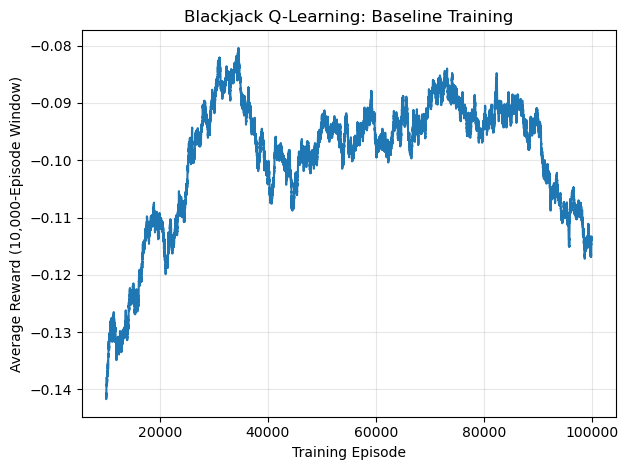

In [3]:
window = 10000

average_rewards = np.convolve(
    total_list,
    np.ones(window) / window,
    mode="valid"
)
episode_numbers = np.arange(window, len(total_list) + 1)

plt.plot(episode_numbers, average_rewards)
plt.title("Blackjack Q-Learning: Baseline Training")
plt.xlabel("Training Episode")
plt.ylabel("Average Reward (10,000-Episode Window)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("baseline_training.png", dpi=300, bbox_inches="tight")
plt.show()

In [4]:
rewards_01, q_alpha_01 = Q(0.1, gamma, epsilon, episodes)
rewards_05, q_alpha_05 = Q(0.5, gamma, epsilon, episodes)
rewards_09, q_alpha_09 = Q(0.9, gamma, epsilon, episodes)

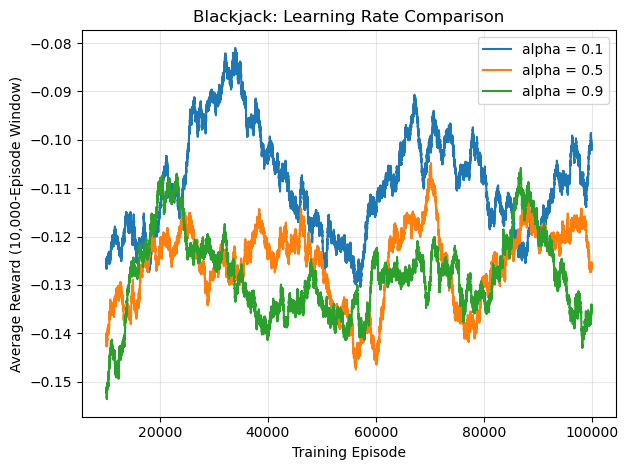

In [5]:
window = 10000

for rewards, label in [
    (rewards_01, "alpha = 0.1"),
    (rewards_05, "alpha = 0.5"),
    (rewards_09, "alpha = 0.9")
]:
    averages = np.convolve(
        rewards,
        np.ones(window) / window,
        mode="valid"
    )

    episode_numbers = np.arange(window, len(rewards) + 1)
    plt.plot(episode_numbers, averages, label=label)

plt.title("Blackjack: Learning Rate Comparison")
plt.xlabel("Training Episode")
plt.ylabel("Average Reward (10,000-Episode Window)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Learning.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
discount_5, q_gamma_5 = Q(alpha, 0.5, epsilon, episodes)
discount_9, q_gamma_9 = Q(alpha, 0.9, epsilon, episodes)
discount_99, q_gamma_99 = Q(alpha, 0.99, epsilon, episodes)

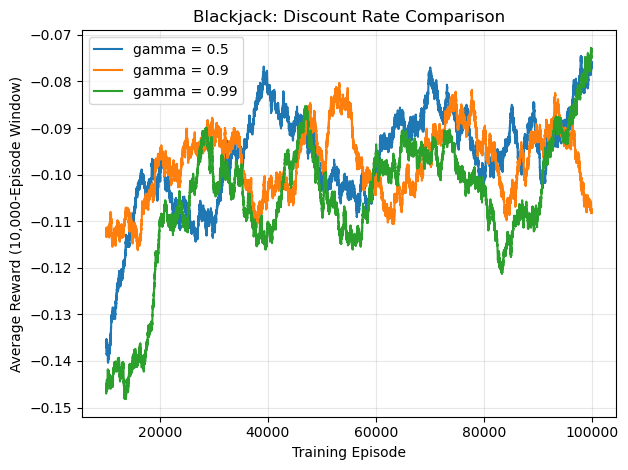

In [7]:
window = 10000

for rewards, label in [
    (discount_5, "gamma = 0.5"),
    (discount_9, "gamma = 0.9"),
    (discount_99, "gamma = 0.99")
]:
    averages = np.convolve(
        rewards,
        np.ones(window) / window,
        mode="valid"
    )

    episode_numbers = np.arange(window, len(rewards) + 1)
    plt.plot(episode_numbers, averages, label=label)

plt.title("Blackjack: Discount Rate Comparison")
plt.xlabel("Training Episode")
plt.ylabel("Average Reward (10,000-Episode Window)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("discount.png", dpi=300, bbox_inches="tight")
plt.show()

In [8]:
epsilon_1, q_epsilon_1 = Q(alpha, gamma, 0.1, episodes)
epsilon_2, q_epsilon_2 = Q(alpha, gamma, 0.2, episodes)
epsilon_3, q_epsilon_3 = Q(alpha, gamma, 0.3, episodes)

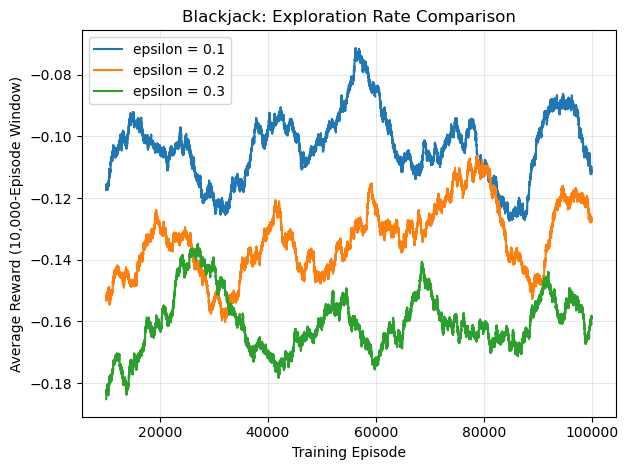

In [9]:
window = 10000

for rewards, label in [
    (epsilon_1, "epsilon = 0.1"),
    (epsilon_2, "epsilon = 0.2"),
    (epsilon_3, "epsilon = 0.3")
]:
    averages = np.convolve(
        rewards,
        np.ones(window) / window,
        mode="valid"
    )

    episode_numbers = np.arange(window, len(rewards) + 1)
    plt.plot(episode_numbers, averages, label=label)

plt.title("Blackjack: Exploration Rate Comparison")
plt.xlabel("Training Episode")
plt.ylabel("Average Reward (10,000-Episode Window)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Exploration.png", dpi=300, bbox_inches="tight")
plt.show()

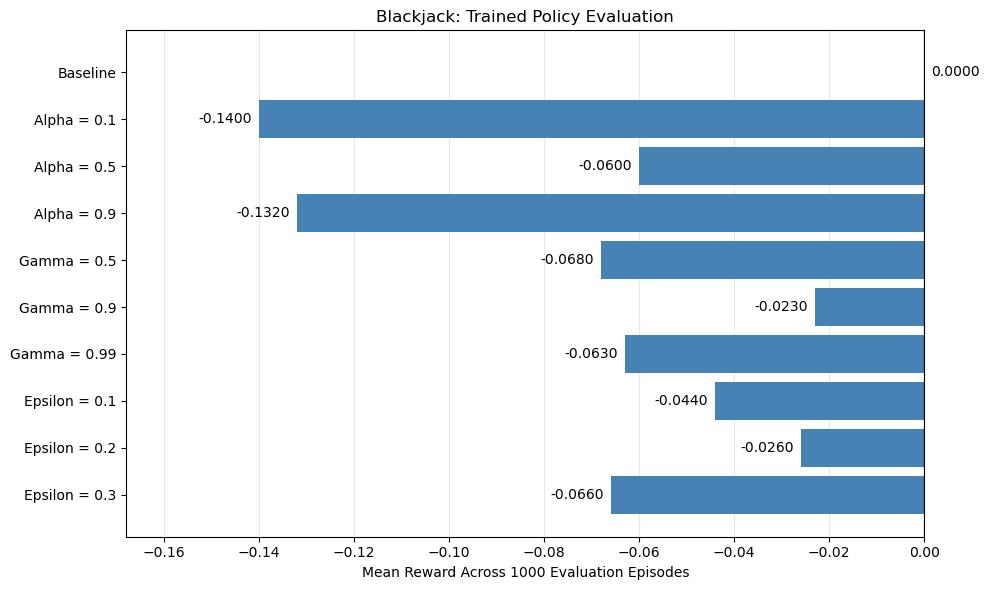

Highest observed mean reward: Baseline

Baseline
Mean reward: 0.0
Win rate: 0.463
Tie rate: 0.074
Loss rate: 0.463

Alpha = 0.1
Mean reward: -0.14
Win rate: 0.394
Tie rate: 0.072
Loss rate: 0.534

Alpha = 0.5
Mean reward: -0.06
Win rate: 0.427
Tie rate: 0.086
Loss rate: 0.487

Alpha = 0.9
Mean reward: -0.132
Win rate: 0.386
Tie rate: 0.096
Loss rate: 0.518

Gamma = 0.5
Mean reward: -0.068
Win rate: 0.424
Tie rate: 0.084
Loss rate: 0.492

Gamma = 0.9
Mean reward: -0.023
Win rate: 0.446
Tie rate: 0.085
Loss rate: 0.469

Gamma = 0.99
Mean reward: -0.063
Win rate: 0.425
Tie rate: 0.087
Loss rate: 0.488

Epsilon = 0.1
Mean reward: -0.044
Win rate: 0.437
Tie rate: 0.082
Loss rate: 0.481

Epsilon = 0.2
Mean reward: -0.026
Win rate: 0.442
Tie rate: 0.09
Loss rate: 0.468

Epsilon = 0.3
Mean reward: -0.066
Win rate: 0.422
Tie rate: 0.09
Loss rate: 0.488



In [10]:
q_tables = {
    "Baseline": baseline_Q,
    "Alpha = 0.1": q_alpha_01,
    "Alpha = 0.5": q_alpha_05,
    "Alpha = 0.9": q_alpha_09,
    "Gamma = 0.5": q_gamma_5,
    "Gamma = 0.9": q_gamma_9,
    "Gamma = 0.99": q_gamma_99,
    "Epsilon = 0.1": q_epsilon_1,
    "Epsilon = 0.2": q_epsilon_2,
    "Epsilon = 0.3": q_epsilon_3
}

evaluation_results = {}
mean_rewards = []

for label, q_table in q_tables.items():
    rewards = np.array(bestQ(1000, q_table))
    evaluation_results[label] = rewards
    mean_rewards.append(np.mean(rewards))

best_index = int(np.argmax(mean_rewards))
colors = ["orange" if i == best_index else "steelblue"
          for i in range(len(mean_rewards))]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(list(q_tables.keys()), mean_rewards, color=colors)
ax.bar_label(bars, fmt="%.4f", padding=5)

ax.axvline(0, color="black", linewidth=0.8)
ax.invert_yaxis()
ax.set_title("Blackjack: Trained Policy Evaluation")
ax.set_xlabel("Mean Reward Across 1000 Evaluation Episodes")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.margins(x=0.2)

plt.tight_layout()
plt.savefig("Trained.png", dpi=300, bbox_inches="tight")
plt.show()

best_name = list(q_tables.keys())[best_index]
print("Highest observed mean reward:", best_name)
print()

for label, rewards in evaluation_results.items():
    print(label)
    print("Mean reward:", np.mean(rewards))
    print("Win rate:", np.mean(rewards == 1))
    print("Tie rate:", np.mean(rewards == 0))
    print("Loss rate:", np.mean(rewards == -1))
    print()

In [13]:
trained_table = q_tables[best_name]

env = gym.make("Blackjack-v1", render_mode="rgb_array")

env = RecordVideo(
    env,
    video_folder="videos",
    episode_trigger=lambda episode_id: True,
    name_prefix="trained-blackjack"
)

try:
    for episode in range(5):
        state, info = env.reset()
        terminated = False
        truncated = False

        while not terminated and not truncated:
            action = int(np.argmax(trained_table[state]))

            state, reward, terminated, truncated, info = env.step(action)
finally:
    env.close()

C:\Users\owenr\anaconda3\Lib\site-packages\gymnasium\wrappers\rendering.py:298: UserWarning: WARN: Overwriting existing videos at C:\Users\owenr\videos folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(
